# Basic data exploration — Leonard

A field-by-field tour of the **actual competition training data**, including nested Pokémon, moves, states, boosts, types, and effects. Saved outputs let you browse immediately; rerun with the project `.venv` Python kernel to refresh.

**Contents:** files and schema → one battle → all-field missingness → numeric values → complete categorical values → containers and placeholders → plots → test/submission structure → supplied type chart → exported summaries.

Detailed distributions are computed from training data only. Test data is used solely for structural and submission checks. No models are fitted, and source files are never modified. Numeric fields have ranges, quantiles, unique counts, and frequent values; every observed categorical value is listed in expandable tables. Exact scalar value counts are also exported locally.

In [ ]:
from pathlib import Path
from collections import Counter, defaultdict
import json
import sys
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/pokemon_challenge").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open the FDS_Challenge_26 repository folder first.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from pokemon_challenge.paths import data_dir, output_dir
from pokemon_challenge.data import iter_battles
DATA = data_dir()
OUT = output_dir("leonard", "basic_data_exploration")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})

# HTML display works in Jupyter; the scroll areas keep complete tables readable.
class HTMLView:
    def __init__(self, markup): self.markup = markup
    def _repr_html_(self): return self.markup
    def __repr__(self): return "HTML table (open the notebook's rich output to view)"

def full_table(frame, height=420):
    display(HTMLView(f'<div style="max-height:{height}px;overflow:auto">' + frame.to_html(index=False, escape=True) + '</div>'))

files = [DATA / n for n in ("train.jsonl", "test.jsonl", "sample_submission.csv", "type_chart_gen2.csv")]
for p in files:
    if not p.is_file(): raise FileNotFoundError(p)
display(pd.DataFrame([{"file": p.name, "MiB": round(p.stat().st_size / 1024**2, 2)} for p in files]))
print("Data:", DATA)
print("Exported summaries:", OUT)


,file,MiB
0,train.jsonl,156.51
1,test.jsonl,78.09
2,sample_submission.csv,0.03
3,type_chart_gen2.csv,0.00


Data: /Users/leo/Library/CloudStorage/OneDrive-Persönlich/3_Programming/Workspaces/Erasmus/FDS/Pokemon/FDS_Challenge_26/data/raw
Exported summaries: /Users/leo/Library/CloudStorage/OneDrive-Persönlich/3_Programming/Workspaces/Erasmus/FDS/Pokemon/FDS_Challenge_26/outputs/leonard/basic_data_exploration


## 1. What does a battle look like?

Each JSONL line is one battle dictionary. The team is a list of Pokémon dictionaries; the timeline is a list of turn dictionaries. A turn contains two state dictionaries and two optional move dictionaries.

Below, the raw preview shows **one team member and one turn** to keep it readable. The subsequent tables show the complete team and all 30 observed turns for this battle. Change `EXAMPLE_INDEX` and rerun this cell to inspect another battle.

In [2]:
EXAMPLE_INDEX = 0
from itertools import islice
example = next(islice(iter_battles(DATA / "train.jsonl"), EXAMPLE_INDEX, None))
display(pd.DataFrame([{"field": k, "Python_type": type(v).__name__,
                       "length_if_container": len(v) if isinstance(v, (list, dict)) else None}
                      for k, v in example.items()]))
preview = {**example, "p1_team_details": example["p1_team_details"][:1],
           "battle_timeline": example["battle_timeline"][:1]}
print(json.dumps(preview, indent=2))
print("Player 1's complete initial team:")
full_table(pd.DataFrame(example["p1_team_details"]))
print("Player 2's initial lead:")
full_table(pd.DataFrame([example["p2_lead_details"]]))
print("All observed turns, flattened into columns:")
example_turns = pd.json_normalize(example["battle_timeline"])
full_table(example_turns, height=520)


,field,Python_type,length_if_container
0,battle_id,int,NaN
1,p1_team_details,list,6.0
2,p2_lead_details,dict,9.0
3,battle_timeline,list,30.0
4,player_won,int,NaN


{
  "battle_id": 0,
  "p1_team_details": [
    {
      "name": "tyranitar",
      "level": 100,
      "types": [
        "dark",
        "rock"
      ],
      "base_hp": 100,
      "base_atk": 134,
      "base_def": 110,
      "base_spa": 95,
      "base_spd": 100,
      "base_spe": 61,
      "item": "leftovers"
    }
  ],
  "p2_lead_details": {
    "name": "forretress",
    "level": 100,
    "types": [
      "bug",
      "steel"
    ],
    "base_hp": 75,
    "base_atk": 90,
    "base_def": 140,
    "base_spa": 60,
    "base_spd": 60,
    "base_spe": 40
  },
  "battle_timeline": [
    {
      "turn": 1,
      "p1_pokemon_state": {
        "name": "tyranitar",
        "hp_pct": 1.0,
        "status": "nostatus",
        "effects": [
          "noeffect"
        ],
        "boosts": {
          "atk": 0,
          "def": 0,
          "spa": 0,
          "spd": 0,
          "spe": 0
        }
      },
      "p1_move_details": {
        "name": "earthquake",
        "type": "ground",
     

name,level,types,base_hp,base_atk,base_def,base_spa,base_spd,base_spe,item
tyranitar,100,"[dark, rock]",100,134,110,95,100,61,leftovers
typhlosion,100,"[fire, notype]",78,84,78,109,85,100,mintberry
golem,100,"[ground, rock]",80,110,130,55,65,45,berserkgene
umbreon,100,"[dark, notype]",95,65,110,60,130,65,leftovers
alakazam,100,"[notype, psychic]",55,50,45,135,85,120,leftovers
raikou,100,"[electric, notype]",90,85,75,115,100,115,leftovers


Player 2's initial lead:


name,level,types,base_hp,base_atk,base_def,base_spa,base_spd,base_spe
forretress,100,"[bug, steel]",75,90,140,60,60,40


All observed turns, flattened into columns:


turn,p1_pokemon_state.name,p1_pokemon_state.hp_pct,p1_pokemon_state.status,p1_pokemon_state.effects,p1_pokemon_state.boosts.atk,p1_pokemon_state.boosts.def,p1_pokemon_state.boosts.spa,p1_pokemon_state.boosts.spd,p1_pokemon_state.boosts.spe,p1_move_details.name,p1_move_details.type,p1_move_details.category,p1_move_details.base_power,p1_move_details.accuracy,p1_move_details.priority,p2_pokemon_state.name,p2_pokemon_state.hp_pct,p2_pokemon_state.status,p2_pokemon_state.effects,p2_pokemon_state.boosts.atk,p2_pokemon_state.boosts.def,p2_pokemon_state.boosts.spa,p2_pokemon_state.boosts.spd,p2_pokemon_state.boosts.spe,p2_move_details.name,p2_move_details.type,p2_move_details.category,p2_move_details.base_power,p2_move_details.accuracy,p2_move_details.priority,p1_move_details,p2_move_details
1,tyranitar,1.00,nostatus,[noeffect],0,0,0,0,0,earthquake,ground,physical,100.0,1.00,0.0,forretress,0.86,nostatus,[noeffect],0,0,0,0,0,toxic,poison,status,0.0,0.85,0.0,NaN,NaN
2,typhlosion,1.00,tox,[noeffect],0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,forretress,0.93,nostatus,[noeffect],0,0,0,0,0,toxic,poison,status,0.0,0.85,0.0,NaN,NaN
3,typhlosion,0.94,tox,[noeffect],0,0,0,0,0,fireblast,fire,special,120.0,0.85,0.0,zapdos,0.61,nostatus,[noeffect],0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,typhlosion,0.03,tox,[noeffect],0,0,0,0,0,fireblast,fire,special,120.0,0.85,0.0,zapdos,0.26,nostatus,[noeffect],0,0,0,0,0,hiddenpower,normal,physical,0.0,1.00,0.0,NaN,NaN
5,typhlosion,1.00,nostatus,[noeffect],0,0,0,0,0,rest,psychic,status,0.0,1.00,0.0,snorlax,1.00,nostatus,[noeffect],0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,typhlosion,1.00,nostatus,[noeffect],0,0,0,0,0,thunderpunch,electric,special,75.0,1.00,0.0,snorlax,0.94,nostatus,[noeffect],1,1,0,0,-1,curse,threequestionmarks,status,0.0,1.00,0.0,NaN,NaN
7,typhlosion,1.00,nostatus,[noeffect],0,0,0,0,0,fireblast,fire,special,120.0,0.85,0.0,snorlax,0.75,nostatus,[noeffect],2,2,0,0,-2,curse,threequestionmarks,status,0.0,1.00,0.0,NaN,NaN
8,typhlosion,0.02,nostatus,[noeffect],0,0,0,0,0,fireblast,fire,special,120.0,0.85,0.0,snorlax,0.36,nostatus,[noeffect],2,2,0,0,-2,doubleedge,normal,physical,120.0,1.00,0.0,NaN,NaN
9,typhlosion,0.02,nostatus,[noeffect],0,0,0,0,0,fireblast,fire,special,120.0,0.85,0.0,snorlax,1.00,slp,[noeffect],2,2,0,0,-2,rest,psychic,status,0.0,1.00,0.0,NaN,NaN
10,typhlosion,1.00,slp,[noeffect],0,0,0,0,0,rest,psychic,status,0.0,1.00,0.0,snorlax,1.00,slp,[noeffect],2,2,0,0,-2,sleeptalk,normal,status,0.0,1.00,0.0,NaN,NaN


## 2. Profile every nested field across all training battles

The profiler walks every dictionary and list, without retaining the full dataset in memory. Paths containing `[]` refer to individual list elements: `p1_team_details[].types[]`, for example, counts Pokémon type slots.

**How to read missingness:**

- **Absent:** a key is not present in an existing parent dictionary.
- **Explicit null:** the key exists and its value is JSON `null`.
- **Empty list/dictionary/string:** present but empty; reported separately.
- **Missing parent:** if an entire move is `null`, its child `name` does not get a synthetic null observation. Its absence is explained by the move object's null count. Child percentages use only existing parent dictionaries.

This distinction avoids labelling all unrecorded move attributes as independent errors. Counts are per field occurrence, not always per battle: team fields can have 60,000 observations, and turn fields 300,000.

In [3]:
def new_profile():
    return {"types": Counter(), "count": 0, "nulls": 0, "empty_strings": 0,
            "empty_lists": 0, "empty_dicts": 0, "lengths": Counter(),
            "values": Counter(), "numeric": Counter()}

profiles = defaultdict(new_profile)
dictionary_counts = Counter()
parent_paths = {}

def walk(value, path="battle", parent=None):
    info = profiles[path]
    info["count"] += 1
    kind = "null" if value is None else type(value).__name__
    info["types"][kind] += 1
    if parent is not None: parent_paths[path] = parent
    if value is None:
        info["nulls"] += 1
    elif isinstance(value, dict):
        dictionary_counts[path] += 1
        info["lengths"][len(value)] += 1
        info["empty_dicts"] += int(not value)
        for key, child in value.items(): walk(child, path + "." + key, path)
    elif isinstance(value, list):
        info["lengths"][len(value)] += 1
        info["empty_lists"] += int(not value)
        for child in value: walk(child, path + "[]")
    else:
        info["values"][json.dumps(value, ensure_ascii=False)] += 1
        info["empty_strings"] += int(value == "")
        if isinstance(value, (int, float)) and not isinstance(value, bool):
            info["numeric"][value] += 1

battle_rows = []
team_species = Counter()
for battle in iter_battles(DATA / "train.jsonl"):
    walk(battle)
    battle_rows.append({"battle_id": battle["battle_id"], "player_won": battle.get("player_won"),
                        "team_size": len(battle.get("p1_team_details") or []),
                        "observed_turns": len(battle.get("battle_timeline") or [])})
    team_species.update(p.get("name", "<absent>") for p in battle.get("p1_team_details", []))
train_overview = pd.DataFrame(battle_rows)
print(f"Scanned {len(train_overview):,} training battles and {len(profiles)} distinct field paths.")


Scanned 10,000 training battles and 68 distinct field paths.


In [4]:
schema_rows = []
for path, info in sorted(profiles.items()):
    parent = parent_paths.get(path)
    expected = dictionary_counts[parent] if parent is not None else info["count"]
    absent = expected - info["count"]
    schema_rows.append({
        "field": path, "types": ", ".join(f"{k}: {v:,}" for k, v in info["types"].items()),
        "parent_contexts": expected, "present": info["count"], "absent": absent,
        "null": info["nulls"],
        "absent_or_null_pct": round(100 * (absent + info["nulls"]) / expected, 3) if expected else None,
        "empty_string": info["empty_strings"], "empty_list": info["empty_lists"],
        "empty_dict": info["empty_dicts"], "distinct_scalar_values": len(info["values"])
    })
schema = pd.DataFrame(schema_rows)
full_table(schema, height=650)
print("Only fields with absent/null/empty observations:")
missing_fields = schema.loc[schema[["absent", "null", "empty_string", "empty_list", "empty_dict"]].sum(axis=1) > 0]
full_table(missing_fields)
print("No row in this table means no such missing/empty observation was found, not that all semantic information is known.")


field,types,parent_contexts,present,absent,null,absent_or_null_pct,empty_string,empty_list,empty_dict,distinct_scalar_values
battle,"dict: 10,000",10000,10000,0,0,0.000,0,0,0,0
battle.battle_id,"int: 10,000",10000,10000,0,0,0.000,0,0,0,10000
battle.battle_timeline,"list: 10,000",10000,10000,0,0,0.000,0,0,0,0
battle.battle_timeline[],"dict: 300,000",300000,300000,0,0,0.000,0,0,0,0
battle.battle_timeline[].p1_move_details,"dict: 240,623, null: 59,377",300000,300000,0,59377,19.792,0,0,0,0
battle.battle_timeline[].p1_move_details.accuracy,"float: 240,623",240623,240623,0,0,0.000,0,0,0,10
battle.battle_timeline[].p1_move_details.base_power,"int: 240,623",240623,240623,0,0,0.000,0,0,0,25
battle.battle_timeline[].p1_move_details.category,"str: 240,623",240623,240623,0,0,0.000,0,0,0,3
battle.battle_timeline[].p1_move_details.name,"str: 240,623",240623,240623,0,0,0.000,0,0,0,216
battle.battle_timeline[].p1_move_details.priority,"int: 240,623",240623,240623,0,0,0.000,0,0,0,4


Only fields with absent/null/empty observations:


field,types,parent_contexts,present,absent,null,absent_or_null_pct,empty_string,empty_list,empty_dict,distinct_scalar_values
battle.battle_timeline[].p1_move_details,"dict: 240,623, null: 59,377",300000,300000,0,59377,19.792,0,0,0,0
battle.battle_timeline[].p2_move_details,"dict: 240,400, null: 59,600",300000,300000,0,59600,19.867,0,0,0,0


No row in this table means no such missing/empty observation was found, not that all semantic information is known.


## 3. Numeric values for every numeric field

For each numeric field: number of observed numeric values, number of distinct values, minimum, quartiles, median, maximum, mean, standard deviation, and ten most frequent values. Numeric summaries exclude nulls. Booleans, if present, are treated as categories.

`battle_id` is an identifier, not a predictive variable. `hp_pct` is an observed health **fraction**, while `base_hp` is a Pokémon's base stat. Accuracy and health fraction units should be checked against their observed ranges rather than inferred from names.

In [5]:
numeric_rows = []
for path, info in sorted(profiles.items()):
    counts = info["numeric"]
    if not counts: continue
    # Expand only this scalar field for exact ordinary sample statistics/quantiles.
    values = np.repeat(np.array(list(counts), dtype=float), list(counts.values()))
    description = pd.Series(values).describe()
    numeric_rows.append({"field": path, "numeric_count": len(values), "unique": len(counts),
        "min": description["min"], "p25": description["25%"], "median": description["50%"],
        "p75": description["75%"], "max": description["max"], "mean": description["mean"],
        "std": description["std"], "frequent_values (count)": "; ".join(f"{v:g} ({n:,})" for v, n in counts.most_common(10))})
numeric_summary = pd.DataFrame(numeric_rows)
full_table(numeric_summary.round(4), height=650)


field,numeric_count,unique,min,p25,median,p75,max,mean,std,frequent_values (count)
battle.battle_id,10000,10000,0.0,2499.7500,4999.50,7499.25,9999.0,4999.5000,2886.8957,0 (1); 1 (1); 2 (1); 3 (1); 4 (1); 5 (1); 6 (1); 7 (1); 8 (1); 9 (1)
battle.battle_timeline[].p1_move_details.accuracy,240623,10,0.5,1.0000,1.00,1.00,1.0,0.9466,0.1082,"1 (184,915); 0.7 (18,561); 0.85 (13,906); 0.75 (8,288); 0.9 (7,834); 0.8 (3,074); 0.5 (2,411); 0.6 (1,059); 0.95 (435); 0.55 (140)"
battle.battle_timeline[].p1_move_details.base_power,240623,25,0.0,0.0000,20.00,95.00,250.0,50.8567,55.5094,"0 (116,246); 120 (34,083); 95 (25,269); 100 (18,805); 75 (8,775); 85 (7,987); 90 (7,253); 40 (4,777); 80 (4,697); 20 (4,248)"
battle.battle_timeline[].p1_move_details.priority,240623,4,-1.0,0.0000,0.00,0.00,2.0,-0.0346,0.2718,"0 (227,248); -1 (11,629); 2 (1,563); 1 (183)"
battle.battle_timeline[].p1_pokemon_state.boosts.atk,300000,13,-6.0,0.0000,0.00,0.00,6.0,0.1559,0.7730,"0 (271,294); 1 (13,820); 2 (6,798); 6 (2,111); 3 (1,459); -2 (1,239); 4 (1,139); -1 (829); 5 (751); -6 (241)"
battle.battle_timeline[].p1_pokemon_state.boosts.def,300000,12,-5.0,0.0000,0.00,0.00,6.0,0.1337,0.5963,"0 (276,620); 1 (14,088); 2 (4,958); 3 (1,513); 4 (1,000); 6 (960); 5 (497); -2 (231); -1 (102); -4 (29)"
battle.battle_timeline[].p1_pokemon_state.boosts.spa,300000,7,0.0,0.0000,0.00,0.00,6.0,0.0160,0.1935,"0 (297,109); 1 (1,833); 2 (591); 3 (231); 4 (116); 5 (104); 6 (16)"
battle.battle_timeline[].p1_pokemon_state.boosts.spd,300000,7,-2.0,0.0000,0.00,0.00,6.0,-0.0024,0.1035,"0 (298,392); -1 (1,247); 1 (162); 2 (101); -2 (44); 4 (36); 6 (18)"
battle.battle_timeline[].p1_pokemon_state.boosts.spe,300000,11,-6.0,0.0000,0.00,0.00,6.0,-0.1182,0.5955,"0 (276,587); -1 (13,776); -2 (4,452); -3 (1,469); 2 (1,252); -6 (961); -4 (792); -5 (482); 1 (161); 4 (58)"
battle.battle_timeline[].p1_pokemon_state.hp_pct,300000,8110,0.0,0.6139,0.88,1.00,1.0,0.7606,0.2974,"1 (105,356); 0 (16,882); 0.94 (11,468); 0.88 (5,149); 0.99 (4,830); 0.82 (3,046); 0.76 (2,469); 0.83 (1,951); 0.79 (1,909); 0.75 (1,893)"


## 4. All observed categorical values, for every categorical field

Expand any field to see **all** its observed values and counts. Percentages use the field's non-null scalar observations. Lists are profiled at element level, so both type slots and repeated status/effect observations contribute counts.

The catalogue includes Pokémon names, items, types, statuses, effects, move names/categories, and any boolean fields. No arbitrary top-N truncation is applied here. Values are quoted using JSON notation so empty strings and placeholder strings remain distinguishable.

In [6]:
categorical_parts = []
for path, info in sorted(profiles.items()):
    category_counts = [(token, count) for token, count in info["values"].items()
                       if isinstance(json.loads(token), (str, bool))]
    if not category_counts: continue
    total = sum(count for _, count in category_counts)
    frame = pd.DataFrame(sorted(category_counts, key=lambda x: (-x[1], x[0])), columns=["value", "count"])
    frame["percent"] = (frame["count"] / total * 100).round(3)
    categorical_parts.append('<details style="margin:10px 0"><summary><b>' + html.escape(path)
        + f'</b> — {len(frame):,} values; {total:,} observations</summary>'
        + '<div style="max-height:360px;overflow:auto">' + frame.to_html(index=False, escape=True)
        + '</div></details>')
display(HTMLView("".join(categorical_parts)))
print("Expand each field above for its full categorical vocabulary.")


value,count,percent
"""status""",102277,42.505
"""physical""",71128,29.560
"""special""",67218,27.935
value,count,percent
"""thunder""",18053,7.503
"""earthquake""",13882,5.769
"""rest""",11859,4.928
"""curse""",11329,4.708
"""hiddenpower""",11189,4.650
"""spikes""",11103,4.614


Expand each field above for its full categorical vocabulary.


## 5. Containers and explicit placeholder values

A present list can contain no entries, one entry, or several entries. The length distributions below cover every dictionary/list field. For dictionaries, length means number of keys; for lists, number of elements. The `[]` paths may themselves be dictionaries.

`notype`, `nostatus`, and `noeffect` are explicit recorded strings, not JSON nulls. They may mean an unused type slot or no recorded condition. A null move indicates no move details were recorded; this inspection alone does not establish why.

In [7]:
containers = []
placeholders = []
for path, info in sorted(profiles.items()):
    if info["lengths"]:
        containers.append({"field": path, "length_or_key_count: occurrences":
                           "; ".join(f"{n}: {count:,}" for n, count in sorted(info["lengths"].items()))})
    for word in ("notype", "nostatus", "noeffect", ""):
        count = info["values"].get(json.dumps(word), 0)
        if count: placeholders.append({"field": path, "literal_value": json.dumps(word), "count": count})
full_table(pd.DataFrame(containers), height=450)
full_table(pd.DataFrame(placeholders))


field,length_or_key_count: occurrences
battle,"5: 10,000"
battle.battle_timeline,"30: 10,000"
battle.battle_timeline[],"5: 300,000"
battle.battle_timeline[].p1_move_details,"6: 240,623"
battle.battle_timeline[].p1_pokemon_state,"5: 300,000"
battle.battle_timeline[].p1_pokemon_state.boosts,"5: 300,000"
battle.battle_timeline[].p1_pokemon_state.effects,"1: 300,000"
battle.battle_timeline[].p2_move_details,"6: 240,400"
battle.battle_timeline[].p2_pokemon_state,"5: 300,000"
battle.battle_timeline[].p2_pokemon_state.boosts,"5: 300,000"


field,literal_value,count
battle.battle_timeline[].p1_pokemon_state.effects[],"""noeffect""",284916
battle.battle_timeline[].p1_pokemon_state.status,"""nostatus""",219205
battle.battle_timeline[].p2_pokemon_state.effects[],"""noeffect""",284698
battle.battle_timeline[].p2_pokemon_state.status,"""nostatus""",229175
battle.p1_team_details[].types[],"""notype""",24458
battle.p2_lead_details.types[],"""notype""",4444


## 6. A few views of the data

These charts summarize the target and team composition, and show the selected example's active-Pokémon health. The HP lines do **not** represent total remaining team health. A switch can make a line jump; the observations do not establish the precise timing of every action.

,battles,percent
player_won,,
0,5000,50.0
1,5000,50.0


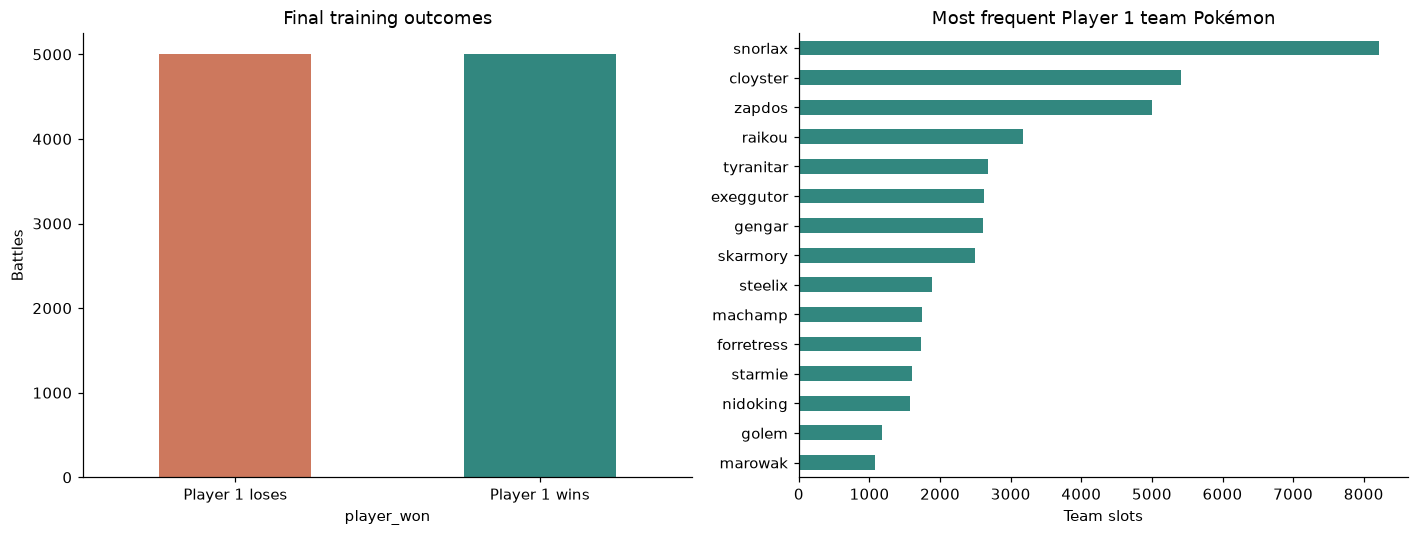

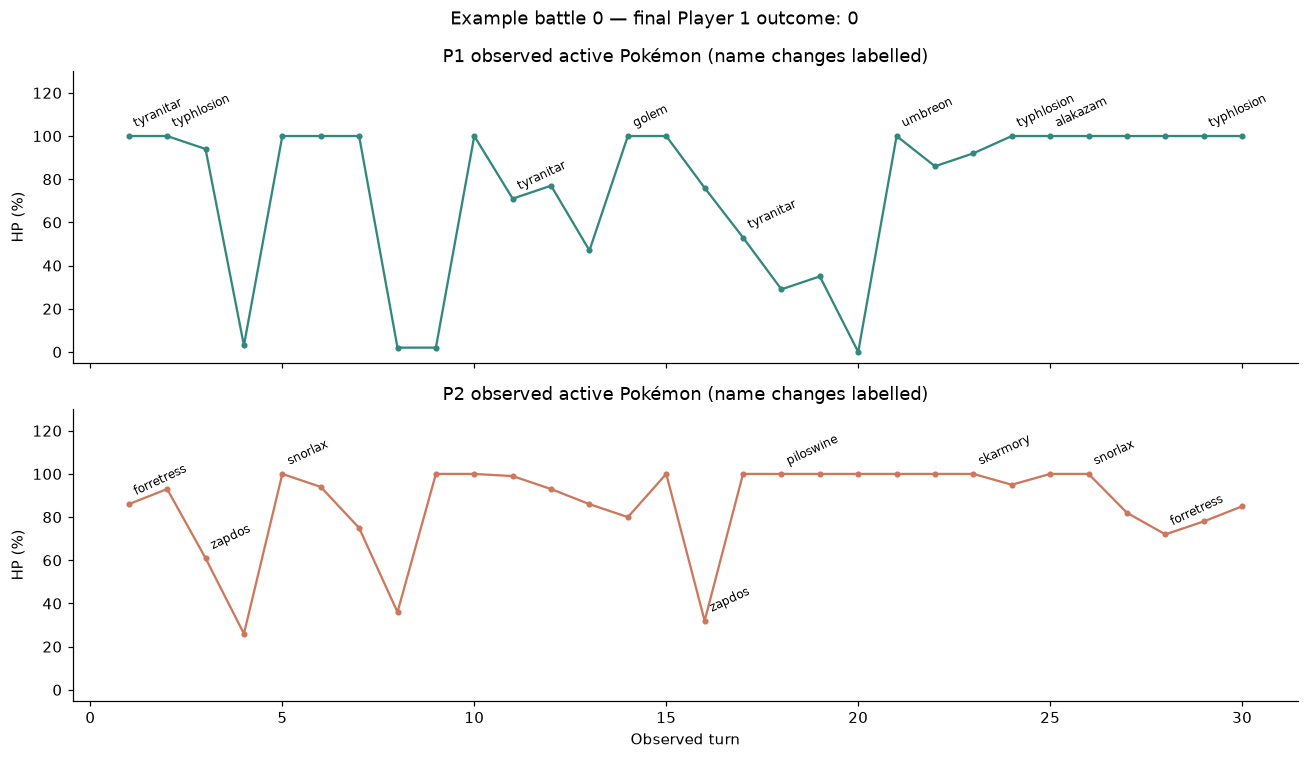

In [8]:
labels = train_overview["player_won"].value_counts().sort_index()
label_table = labels.rename_axis("player_won").to_frame("battles")
label_table["percent"] = labels / len(train_overview) * 100
display(label_table)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels.rename(index={0: "Player 1 loses", 1: "Player 1 wins"}).plot.bar(ax=axes[0], color=["#cd785d", "#32877f"], rot=0)
axes[0].set(title="Final training outcomes", ylabel="Battles")
pd.Series(team_species).nlargest(15).sort_values().plot.barh(ax=axes[1], color="#32877f")
axes[1].set(title="Most frequent Player 1 team Pokémon", xlabel="Team slots")
fig.tight_layout()
display(fig)
plt.close(fig)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True)
for ax, side, color in zip(axes, ("p1", "p2"), ("#32877f", "#cd785d")):
    turns = example["battle_timeline"]
    xs = [t["turn"] for t in turns]
    ys = [(t.get(f"{side}_pokemon_state") or {}).get("hp_pct", np.nan) * 100 for t in turns]
    names = [(t.get(f"{side}_pokemon_state") or {}).get("name", "unknown") for t in turns]
    ax.plot(xs, ys, marker="o", markersize=3, color=color)
    for i, name in enumerate(names):
        if i == 0 or name != names[i-1]:
            ax.annotate(name, (xs[i], ys[i]), xytext=(2, 6), textcoords="offset points", fontsize=8, rotation=25)
    ax.set(title=f"{side.upper()} observed active Pokémon (name changes labelled)", ylabel="HP (%)", ylim=(-5, 130))
axes[-1].set_xlabel("Observed turn")
fig.suptitle(f"Example battle {example['battle_id']} — final Player 1 outcome: {example['player_won']}")
fig.tight_layout()
display(fig)
plt.close(fig)


## 7. Basic integrity checks and the submission template

Train and test battle IDs are allowed to overlap because the files restart numbering. Test distributions are not explored for feature selection here. The sample's `player_won` zeros are prediction placeholders, not true test outcomes.

In [9]:
test_ids = []
test_keys = Counter()
test_lengths = Counter()
test_with_target = 0
for battle in iter_battles(DATA / "test.jsonl"):
    test_ids.append(battle["battle_id"])
    test_keys.update(battle.keys())
    test_lengths[len(battle.get("battle_timeline") or [])] += 1
    test_with_target += int("player_won" in battle)
sample = pd.read_csv(DATA / "sample_submission.csv")
print("Training battles:", len(train_overview), "| test battles:", len(test_ids))
print("Test field presence:", dict(test_keys))
print("Test observed timeline lengths:", dict(test_lengths))
print("IDs shared between files:", len(set(train_overview["battle_id"]) & set(test_ids)))
display(sample.head(10))
checks = pd.Series({
    "training IDs unique": train_overview["battle_id"].is_unique,
    "training labels binary and not missing": train_overview["player_won"].isin([0, 1]).all(),
    "training teams all have six members": train_overview["team_size"].eq(6).all(),
    "training timelines all have 30 entries": train_overview["observed_turns"].eq(30).all(),
    "test IDs unique": len(set(test_ids)) == len(test_ids),
    "test target field absent": test_with_target == 0,
    "sample columns correct": list(sample.columns) == ["battle_id", "player_won"],
    "sample IDs unique and not missing": sample["battle_id"].is_unique and sample["battle_id"].notna().all(),
    "sample IDs exactly match test": set(sample["battle_id"]) == set(test_ids) and len(sample) == len(test_ids),
}, name="passed")
display(checks.to_frame())
# Show failures rather than silently dropping rows or changing the source data.
if not checks.all(): print("Investigate the failed checks before modelling.")


Training battles: 10000 | test battles: 5000
Test field presence: {'battle_id': 5000, 'p1_team_details': 5000, 'p2_lead_details': 5000, 'battle_timeline': 5000}
Test observed timeline lengths: {30: 5000}
IDs shared between files: 5000


,battle_id,player_won
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,0
7,7,0
8,8,0
9,9,0


,passed
training IDs unique,True
training labels binary and not missing,True
training teams all have six members,True
training timelines all have 30 entries,True
test IDs unique,True
test target field absent,True
sample columns correct,True
sample IDs unique and not missing,True
sample IDs exactly match test,True


## 8. Variables in the supplied type chart

This is a permitted auxiliary file, separate from the battle records. Inspect all its columns, missingness, distinct values, and every supplied row. The CSV lists non-neutral matchups; interpreting omitted pairs as 1× would be a later feature-engineering decision.

In [10]:
type_chart = pd.read_csv(DATA / "type_chart_gen2.csv")
chart_profiles = []
for col in type_chart:
    series = type_chart[col]
    chart_profiles.append({"column": col, "dtype": str(series.dtype), "rows": len(series),
                           "missing": int(series.isna().sum()), "unique": int(series.nunique()),
                           "observed_values": ", ".join(map(str, sorted(series.dropna().unique())))})
full_table(pd.DataFrame(chart_profiles))
print("All supplied type chart rows:")
full_table(type_chart, height=500)
print("Duplicate attacking/defending type pairs:", type_chart.duplicated(["attacking_type", "defending_type"]).sum())


column,dtype,rows,missing,unique,observed_values
attacking_type,str,110,0,17,"bug, dark, dragon, electric, fighting, fire, flying, ghost, grass, ground, ice, normal, poison, psychic, rock, steel, water"
defending_type,str,110,0,17,"bug, dark, dragon, electric, fighting, fire, flying, ghost, grass, ground, ice, normal, poison, psychic, rock, steel, water"
multiplier,float64,110,0,3,"0.0, 0.5, 2.0"


All supplied type chart rows:


attacking_type,defending_type,multiplier
normal,rock,0.5
normal,ghost,0.0
normal,steel,0.5
fire,fire,0.5
fire,water,0.5
fire,grass,2.0
fire,ice,2.0
fire,bug,2.0
fire,rock,0.5
fire,dragon,0.5


Duplicate attacking/defending type pairs: 0


## 9. Save complete summaries for further inspection

The notebook's tables are descriptive views. The following CSV files retain every scalar value/count, including all numeric values and IDs, so numeric output need not print thousands of rows. They are generated under `outputs/leonard/basic_data_exploration/`, which is ignored by Git. The notebook keeps its saved tables and charts; no raw data file is copied into the repository history.

In [11]:
schema.to_csv(OUT / "field_schema_and_missingness.csv", index=False)
numeric_summary.to_csv(OUT / "numeric_summary.csv", index=False)
pd.DataFrame(containers).to_csv(OUT / "container_lengths.csv", index=False)
with (OUT / "all_scalar_value_counts.csv").open("w", newline="", encoding="utf-8") as stream:
    import csv
    writer = csv.writer(stream)
    writer.writerow(["field", "value_json", "count", "percent_of_non_null_scalar_values"])
    for path, info in sorted(profiles.items()):
        total = sum(info["values"].values())
        for token, count in info["values"].most_common():
            writer.writerow([path, token, count, round(100 * count / total, 6)])
for p in sorted(OUT.glob("*.csv")): print(p.relative_to(ROOT) if p.is_relative_to(ROOT) else p)


outputs/leonard/basic_data_exploration/all_scalar_value_counts.csv
outputs/leonard/basic_data_exploration/container_lengths.csv
outputs/leonard/basic_data_exploration/field_schema_and_missingness.csv
outputs/leonard/basic_data_exploration/numeric_summary.csv


## Interpretation and next questions

- Use the all-field schema table as the data dictionary: it includes fields nested inside lists and boosts.
- Missing move objects differ from placeholders and from absent dictionary keys; determine appropriate handling before feature extraction.
- Repeated turn observations are not independent training examples. Keep all observations of a battle together during validation.
- Initial knowledge is asymmetric: Player 1's complete team versus Player 2's lead, plus the observed timeline.
- A fixed 30-entry observation window does not tell us the final match length. Even a strong-looking position may lose later.
- Target balance, numeric ranges, and categorical vocabularies describe this training sample. They do not establish causality or guarantee future coverage.

Before modelling: investigate surprising ranges or mixed types, decide how placeholders should be represented, and agree on battle-level validation. This notebook makes no changes to the shared feature or model implementation.